# Reto AgroCebada FIRA 2026
## Libreta 03 - Validacion Robusta y Ablacion

> *"¿Cuanto del desempeno viene de la ubicacion y cuanto de las variables agronomicas?"*

### Seccion del Reporte que alimenta esta libreta
| Seccion del Reporte | Contenido generado aqui |
|---|---|
| **Resultados y Discusion** | Validacion (interpolacion vs. zonas nuevas), comparativa de modelos, diferencias pareadas, ablacion por bloques, prueba de residuos |

### El problema que resolvemos aqui
En agricultura de precision es comun evaluar modelos con validaciones que **no separan observaciones espacialmente cercanas**. Cuando parcelas vecinas comparten manejo, suelo y microclima, un algoritmo flexible puede *memorizar la ubicacion* y reportar un error que no se sostiene al predecir en zonas nuevas. La Primera Ley de Tobler lo anticipa: las cosas cercanas estan mas relacionadas que las lejanas.

### Objetivos de esta libreta
1. Evaluar con tres esquemas: **RepeatedKFold** (parcelas intercaladas = interpolacion), **GroupKFold por celdas CHIRPS** y **Leave-One-Group-Out por municipio** (zonas nuevas).
2. Comparar **cinco modelos en los MISMOS folds**: Dummy (media), KNN espacial (solo lat/lon), HGB agronomico (sin coordenadas), HGB final (coordenadas + variables, `SelectKBest`) y el **ensamble 50/50** KNN + HGB final.
3. Calcular **diferencias pareadas por fold** y aplicar la **regla de decision fijada de antemano**.
4. **Ablacion por bloques** de variables (quitar un bloque / usar solo un bloque) bajo RepeatedKFold y LOGO, con diferencias pareadas y su variabilidad.
5. **Prueba de residuos**: ¿los indices satelitales explican lo que el interpolador espacial no explica?

### Hipotesis (se contrastan; no se asume su resultado)
- **H1.** Si el HGB agronomico no supera al KNN espacial bajo validacion espacial, su desempeno proviene sobre todo de la ubicacion.
- **H2.** Si los indices satelitales explican los residuos del KNN (R2 > 0 fuera de muestra), aportan informacion mas alla de la ubicacion.

### Como leer las metricas
- `MAE_pooled`, `RMSE_pooled`, `R2_pooled`: se calculan sobre las predicciones fuera de muestra de las 138 parcelas (en RepeatedKFold, una vez por repeticion y luego se promedian las 3 repeticiones; **no** se promedian las predicciones entre repeticiones).
- `MAE_fold_media +/- MAE_fold_sd`: media y desviacion del MAE **por fold**. En LOGO cada fold es un municipio, asi que la media es un promedio *por municipio* (macro), distinto del MAE pooled (que pondera por parcelas).
- **El +/- es variabilidad entre folds, no un intervalo de confianza**, y los folds de RepeatedKFold no son independientes. Con 138 parcelas la prueba tiene poco poder para detectar diferencias pequenas: "no detectada" no equivale a "inexistente".
- Los hiperparametros se fijaron en el reporte usando estas mismas particiones, por lo que las cifras son ligeramente optimistas.

### Regla de decision (definida ANTES de ver los resultados)
Se entrega el **ensamble** si su MAE medio por fold bajo RepeatedKFold no excede al del KNN en mas de **0.02 t/ha** (`TOLERANCIA_DECISION`).

In [2]:
# ============================================================
# 1. CONFIGURACION MAESTRA Y ENTORNO (LIBRETA 03)
# ============================================================
!pip install -q geopandas shapely pyproj pyshp scikit-learn

import os
import time
import json
import warnings
from pathlib import Path
from functools import partial

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings('ignore')

sns.set_theme(style="whitegrid", palette="viridis")
plt.rcParams['figure.dpi'] = 120
plt.rcParams['axes.titlesize'] = 12
plt.rcParams['axes.titleweight'] = 'bold'

EN_COLAB = True  # Cambiar a False si el evaluador lo corre en su PC local (GitHub)

if EN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    BASE = Path('/content/drive/MyDrive/Reto_AgroCebada_2026')
else:
    BASE = Path(os.getcwd())

CARPETAS = {
    'raw':           BASE / 'data' / 'raw',
    '01_calidad':    BASE / 'data' / '01_calidad',
    '02_fenologia':  BASE / 'data' / '02_fenologia',
    '03_validacion': BASE / 'data' / '03_validacion',
    '04_shap':       BASE / 'data' / '04_shap',
    '05_final':      BASE / 'data' / '05_final',
    'models':        BASE / 'models',
    'artifacts':     BASE / 'artifacts',
    'reports':       BASE / 'reports',
}

for carpeta in CARPETAS.values():
    carpeta.mkdir(parents=True, exist_ok=True)

def guardar_csv(df, nombre, carpeta='raw'):
    ruta = CARPETAS[carpeta] / nombre
    df.to_csv(ruta, index=False, encoding='utf-8-sig')
    print(f"[OK] Guardado: {ruta}")
    return ruta

def cargar_csv(nombre, carpeta='raw', **kwargs):
    ruta = CARPETAS[carpeta] / nombre
    assert ruta.exists(), f"[ERROR] No existe: {ruta}"
    df = pd.read_csv(ruta, **kwargs)
    print(f"[OK] Cargado: {nombre} ({df.shape[0]} filas x {df.shape[1]} cols)")
    return df

def guardar_figura(fig, nombre, carpeta='reports'):
    ruta = CARPETAS[carpeta] / nombre
    fig.savefig(ruta, dpi=200, bbox_inches='tight')
    print(f"[OK] Grafico guardado: {ruta}")
    return ruta

def listar_archivos(carpeta='raw'):
    ruta = CARPETAS[carpeta]
    archivos = sorted(ruta.iterdir()) if ruta.exists() else []
    if not archivos:
        print(f"Carpeta '{carpeta}' vacia")
    else:
        print(f"Carpeta '{carpeta}': {len(archivos)} archivos")
        for a in archivos:
            tamano = a.stat().st_size
            unidad = 'MB' if tamano > 1e6 else 'KB' if tamano > 1e3 else 'B'
            valor = tamano / 1e6 if tamano > 1e6 else tamano / 1e3 if tamano > 1e3 else tamano
            print(f"   - {a.name} ({valor:.1f} {unidad})")
    return archivos

# Semillas y parametros de validacion
SEMILLA = 999
N_SPLITS_RK = 5
N_REPEATS_RK = 3
TAMANO_CELDA_CHIRPS = 0.05  # ~5 km, aproximacion de la cuadricula CHIRPS

# Constantes de la decision y del modelo final (coinciden con el reporte)
TOLERANCIA_DECISION = 0.02          # t/ha; regla fijada antes del analisis final
SEMILLA_HGB_FINAL = 2026
K_VARS = 20                         # SelectKBest (informacion mutua) dentro de cada fold
FORZAR_COORDS_HGB_FINAL = True      # True: lat/lon entran siempre; False: compiten en SelectKBest

print("[OK] Configuracion completada (Libreta 03)")
print(f"     Semilla global: {SEMILLA}")
print(f"     Tamano de celda CHIRPS: {TAMANO_CELDA_CHIRPS} grados")

Mounted at /content/drive
[OK] Configuracion completada (Libreta 03)
     Semilla global: 999
     Tamano de celda CHIRPS: 0.05 grados


In [3]:
# ============================================================
# 2. CARGA DE DATOS DESDE DRIVE
# ============================================================
print("Cargando artefactos de las Libretas 01 y 02...")

# Matriz integrada de caracteristicas (insumo principal)
X_integrado = cargar_csv('X_integrado_completo.csv', '02_fenologia')

# Variable objetivo (Tabla Maestra)
ruta_y_real = CARPETAS['raw'] / 'extraido' / 'DATASET_RETO_AGRO_2026' / 'ID_area_rendimiento_70_30_Reto_AgroCebada.csv'
if ruta_y_real.exists():
    y_df = pd.read_csv(ruta_y_real)
    print(f"[OK] Cargado: y_rendimiento real desde {ruta_y_real.name} ({y_df.shape[0]} filas)")
else:
    y_df = cargar_csv('y_rendimiento.csv', '01_calidad')

# Metadatos espaciales (coordenadas + municipio + estado) desde el shapefile
RAW = CARPETAS['raw'] / 'extraido'
shp_files = list(RAW.glob('**/*.shp'))
if not shp_files:
    shp_files = list((CARPETAS['raw'] / 'extraido').glob('*/*.shp'))
assert len(shp_files) >= 1, "No se encontro el shapefile de parcelas"
gdf_parcelas = gpd.read_file(shp_files[0])

# Normalizar columna ID
columnas_id = [c for c in gdf_parcelas.columns if 'ID_POL' in c.upper()]
if columnas_id:
    gdf_parcelas = gdf_parcelas.rename(columns={columnas_id[0]: 'ID_POLIGONO'})
gdf_parcelas['ID_POLIGONO'] = gdf_parcelas['ID_POLIGONO'].astype(str).str.strip()

# Extraer coordenadas de centroides (WGS84)
if gdf_parcelas.crs is None:
    gdf_parcelas = gdf_parcelas.set_crs('EPSG:4326')
gdf_wgs84 = gdf_parcelas.to_crs(epsg=4326)
gdf_parcelas['latitud'] = gdf_wgs84.geometry.centroid.y
gdf_parcelas['longitud'] = gdf_wgs84.geometry.centroid.x

# Detectar columnas de municipio/estado
col_municipio = None
col_estado = None
for c in gdf_parcelas.columns:
    if 'munici' in c.lower():
        col_municipio = c
    if 'estado' in c.lower():
        col_estado = c

print(f"\n   Columna de municipio detectada: {col_municipio}")
print(f"   Columna de estado detectada:    {col_estado}")

# Construir tabla de metadatos espaciales
meta_cols = {
    'ID_POLIGONO': gdf_parcelas['ID_POLIGONO'],
    'latitud': gdf_parcelas['latitud'],
    'longitud': gdf_parcelas['longitud']
}
if col_municipio:
    meta_cols['municipio'] = gdf_parcelas[col_municipio]
if col_estado:
    meta_cols['estado'] = gdf_parcelas[col_estado]
df_meta = pd.DataFrame(meta_cols)

print(f"\n[OK] Metadatos espaciales: {len(df_meta)} parcelas")
print(f"[OK] X_integrado:          {X_integrado.shape[0]} parcelas x {X_integrado.shape[1]} variables")
print(f"[OK] y:                    {len(y_df)} etiquetas")

Cargando artefactos de las Libretas 01 y 02...
[OK] Cargado: X_integrado_completo.csv (197 filas x 188 cols)
[OK] Cargado: y_rendimiento real desde ID_area_rendimiento_70_30_Reto_AgroCebada.csv (197 filas)

   Columna de municipio detectada: Municipio
   Columna de estado detectada:    Estado

[OK] Metadatos espaciales: 197 parcelas
[OK] X_integrado:          197 parcelas x 188 variables
[OK] y:                    197 etiquetas


In [4]:
# ============================================================
# 3. PREPARAR MATRIZ DE VALIDACION (138 PARCELAS ETIQUETADAS)
# ============================================================
X_integrado['ID_POLIGONO'] = X_integrado['ID_POLIGONO'].astype(str).str.strip()
y_df['ID_POLIGONO'] = y_df['ID_POLIGONO'].astype(str).str.strip()
df_meta['ID_POLIGONO'] = df_meta['ID_POLIGONO'].astype(str).str.strip()

# IDs de las 59 parcelas a predecir (se usan en la Libreta 04)
ids_prediccion = y_df.loc[y_df['RENDIMIENTO_T_HA'].isna(), 'ID_POLIGONO'].tolist()
assert len(ids_prediccion) == 59, f"Se esperaban 59 parcelas sin rendimiento; hay {len(ids_prediccion)}"
df_prediccion = (X_integrado[X_integrado['ID_POLIGONO'].isin(ids_prediccion)]
                 .merge(df_meta, on='ID_POLIGONO', how='left', validate='one_to_one')
                 .reset_index(drop=True))

# Solo se toma el rendimiento de la tabla maestra porque X_integrado ya contiene AREA_HA
y_df = y_df[['ID_POLIGONO', 'RENDIMIENTO_T_HA']].copy()

df_trabajo = y_df.merge(X_integrado, on='ID_POLIGONO', how='inner', validate='one_to_one')
df_trabajo = df_trabajo.merge(df_meta, on='ID_POLIGONO', how='left', validate='one_to_one')
assert 'AREA_HA' in df_trabajo.columns, "AREA_HA no llego a la matriz de trabajo"
df_trabajo = df_trabajo.dropna(subset=['RENDIMIENTO_T_HA']).reset_index(drop=True)
assert len(df_trabajo) == 138, f"Se esperaban 138 parcelas etiquetadas; hay {len(df_trabajo)}"

print(f"Parcelas con rendimiento conocido: {len(df_trabajo)}")
print(f"Rendimiento: media={df_trabajo['RENDIMIENTO_T_HA'].mean():.2f} t/ha, "
      f"std={df_trabajo['RENDIMIENTO_T_HA'].std():.2f} t/ha")

y = df_trabajo['RENDIMIENTO_T_HA'].reset_index(drop=True)
ids = df_trabajo['ID_POLIGONO'].reset_index(drop=True)
coords = df_trabajo[['latitud', 'longitud']].reset_index(drop=True)

# Variables candidatas: todas las numericas que no son metadatos
COLS_META = ['ID_POLIGONO', 'RENDIMIENTO_T_HA', 'latitud', 'longitud', 'municipio', 'estado']
candidatas = [c for c in df_trabajo.columns if c not in COLS_META]
no_numericas = [c for c in candidatas if not pd.api.types.is_numeric_dtype(df_trabajo[c])]
if no_numericas:
    print(f"[AVISO] Columnas no numericas excluidas: {no_numericas}")
columnas_x = [c for c in candidatas if c not in no_numericas]

# Bloques de variables (por prefijo)
bloques = {
    'suelo_termico': [c for c in columnas_x if c.startswith('suelo_termico')],
    'vegetacion':    [c for c in columnas_x if c.startswith('vegetacion')],
    'fenologia':     [c for c in columnas_x if c.startswith('fenologia')],
    'agua':          [c for c in columnas_x if c.startswith('agua')],
    'topografia':    [c for c in columnas_x if c.startswith(('Elevacion', 'Pendiente'))],
    'clima':         [c for c in columnas_x if c.startswith(('PREC_', 'Tmin_', 'Tmax_'))],
    'fisica':        [c for c in columnas_x if c.startswith('fisica__')],
    'area':          [c for c in columnas_x if c == 'AREA_HA'],
}
sin_bloque = [c for c in columnas_x if not any(c in v for v in bloques.values())]

print("\nBloques de variables:")
for nombre, cols in bloques.items():
    print(f"   {nombre:14s}: {len(cols):3d} variables")
print(f"   {'TOTAL':14s}: {len(columnas_x):3d} variables")
if sin_bloque:
    print(f"[AVISO] Variables sin bloque asignado: {sin_bloque}")

assert len(bloques['clima']) == 21, f"El bloque de clima debe tener 21 variables y tiene {len(bloques['clima'])}."
assert len(bloques['area']) == 1, "AREA_HA debe estar exactamente una vez en la matriz."
assert len(columnas_x) == len(set(columnas_x)), "Hay columnas duplicadas en la matriz."

X_full = df_trabajo[columnas_x].reset_index(drop=True)
X_full_clean = X_full
cols_feat_hgb_final = list(X_full.columns)
X_hgb_final = pd.concat([X_full, coords], axis=1)

Parcelas con rendimiento conocido: 138
Rendimiento: media=3.96 t/ha, std=0.85 t/ha

Bloques de variables:
   suelo_termico :   7 variables
   vegetacion    :   9 variables
   fenologia     : 135 variables
   agua          :   3 variables
   topografia    :   2 variables
   clima         :  21 variables
   fisica        :   9 variables
   area          :   1 variables
   TOTAL         : 187 variables


### Asignacion de Grupos Espaciales

Para probar que el modelo **no memoriza geografia**, definimos dos esquemas de agrupamiento espacial:

1. **Celdas climaticas CHIRPS**: aproximamos la cuadricula de precipitacion CHIRPS (~0.05 grados ~= 5 km) redondeando las coordenadas de cada parcela. Dos parcelas en la misma celda comparten regimen de precipitacion.

2. **Municipios**: agrupamiento administrativo. Las parcelas del mismo municipio comparten contexto regional, suelo y microclima.

**Regla de validacion espacial estricta:** en cada fold, las parcelas del conjunto de validacion pertenecen a grupos (celdas o municipios) que **no aparecen en absoluto** en el conjunto de entrenamiento. Esto elimina la fuga espacial.

In [5]:
# ============================================================
# 4. ASIGNACION DE GRUPOS ESPACIALES
# ============================================================
# --- Celdas CHIRPS (grid de ~0.05 grados) ---
lat_grid = np.floor(df_trabajo['latitud'].values / TAMANO_CELDA_CHIRPS).astype(int)
lon_grid = np.floor(df_trabajo['longitud'].values / TAMANO_CELDA_CHIRPS).astype(int)
df_trabajo['celda_chirps'] = [f"celda_{la}_{lo}" for la, lo in zip(lat_grid, lon_grid)]

# --- Municipios ---
if 'municipio' in df_trabajo.columns:
    df_trabajo['grupo_municipio'] = df_trabajo['municipio'].astype(str)
else:
    df_trabajo['grupo_municipio'] = df_trabajo.get('estado', 'sin_municipio').astype(str)
    print("[AVISO] No se encontro municipio; usando estado como grupo.")

grupos_chirps = df_trabajo['celda_chirps'].reset_index(drop=True)
grupos_municipio = df_trabajo['grupo_municipio'].reset_index(drop=True)

print("=" * 60)
print("GRUPOS ESPACIALES: CELDAS CHIRPS")
print("=" * 60)
conteo_chirps = grupos_chirps.value_counts()
print(f"Numero de celdas unicas: {len(conteo_chirps)}")
print("Distribucion de parcelas por celda:")
print(conteo_chirps.to_string())

print("\n" + "=" * 60)
print("GRUPOS ESPACIALES: MUNICIPIOS")
print("=" * 60)
conteo_muni = grupos_municipio.value_counts()
print(f"Numero de municipios unicos: {len(conteo_muni)}")
print("Distribucion de parcelas por municipio:")
print(conteo_muni.to_string())

grupos_pequenos_chirps = conteo_chirps[conteo_chirps < 3]
grupos_pequenos_muni = conteo_muni[conteo_muni < 3]
if len(grupos_pequenos_chirps) > 0:
    print(f"\n[AVISO] {len(grupos_pequenos_chirps)} celdas CHIRPS tienen <3 parcelas (folds ruidosos).")
if len(grupos_pequenos_muni) > 0:
    print(f"[AVISO] {len(grupos_pequenos_muni)} municipios tienen <3 parcelas (folds ruidosos).")

# Guardar metadatos espaciales de validacion para auditoria y dashboard
cols_meta_export = [c for c in ['ID_POLIGONO', 'estado', 'municipio', 'celda_chirps', 'latitud', 'longitud'] if c in df_trabajo.columns]
guardar_csv(df_trabajo[cols_meta_export], 'metadatos_espaciales_validacion.csv', '03_validacion')

GRUPOS ESPACIALES: CELDAS CHIRPS
Numero de celdas unicas: 23
Distribucion de parcelas por celda:
celda_chirps
celda_397_-1966    34
celda_397_-1965    34
celda_391_-1971    15
celda_391_-1972     8
celda_399_-1969     7
celda_399_-1968     6
celda_396_-1966     5
celda_395_-1966     5
celda_398_-1966     3
celda_392_-1971     3
celda_392_-1972     3
celda_390_-1972     2
celda_398_-1968     2
celda_390_-1973     2
celda_397_-1968     1
celda_395_-1967     1
celda_396_-1968     1
celda_390_-1971     1
celda_398_-1969     1
celda_395_-1968     1
celda_396_-1965     1
celda_394_-1968     1
celda_393_-1972     1

GRUPOS ESPACIALES: MUNICIPIOS
Numero de municipios unicos: 9
Distribucion de parcelas por municipio:
grupo_municipio
Chignahuapan                     71
Calpulalpan                      30
Singuilucan                      16
Almoloya                         10
Cuautepec de Hinojosa             5
Emiliano Zapata                   3
Tepeapulco                        1
Nanacamilpa de

PosixPath('/content/drive/MyDrive/Reto_AgroCebada_2026/data/03_validacion/metadatos_espaciales_validacion.csv')

### Definicion de Modelos y Pipeline

Se evaluan cinco modelos **en los mismos folds**:

| Modelo | Entradas | Proposito |
|---|---|---|
| **Dummy (media)** | — | Linea base: error sin aprender nada |
| **KNN espacial** | Solo latitud/longitud (k=5, pesos por distancia) | Interpolador puro: error "memorizando" ubicacion |
| **HGB agronomico** | Todas las variables **sin** coordenadas | ¿Hay senal agronomica mas alla de la ubicacion? |
| **HGB final** | Coordenadas + variables fisicas/satelitales/clima; `SelectKBest(k=20)` por informacion mutua dentro de cada fold (lr 0.06, 15 hojas, min 5 por hoja, L2=8.0, semilla 2026) | Modelo descrito en el reporte |
| **Ensamble 50/50** | Promedio de KNN espacial y HGB final | Modelo de entrega |

**Prueba de fuego (no un resultado asumido):** si el HGB agronomico no supera al KNN espacial bajo validacion espacial, el desempeno proviene sobre todo de la ubicacion.

In [6]:
# ============================================================
# 5. CONSTRUCCION DE MODELOS Y FUNCIONES DE EVALUACION
# ============================================================
from sklearn.dummy import DummyRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.feature_selection import SelectKBest, mutual_info_regression
from sklearn.model_selection import RepeatedKFold, GroupKFold, LeaveOneGroupOut
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

PARAMS_HGB = {                      # HGB agronomico (sin coordenadas)
    'learning_rate': 0.05, 'max_leaf_nodes': 7, 'min_samples_leaf': 10,
    'l2_regularization': 10.0, 'random_state': SEMILLA,
}
PARAMS_HGB_FINAL = {                # HGB final (coincide con el reporte)
    'learning_rate': 0.06, 'max_leaf_nodes': 15, 'min_samples_leaf': 5,
    'l2_regularization': 8.0, 'random_state': SEMILLA_HGB_FINAL,
}
PARAMS_KNN = {'n_neighbors': 5, 'weights': 'distance'}
COLS_COORDS = ['latitud', 'longitud']


def construir_modelo(tipo, columnas_x=None):
    """Devuelve un Pipeline sin ajustar. Todo el preprocesamiento vive dentro del pipeline (sin fuga entre folds)."""
    if tipo == 'dummy':
        return Pipeline([('dummy', DummyRegressor(strategy='mean'))])
    if tipo == 'knn':
        return Pipeline([('scaler', StandardScaler()), ('knn', KNeighborsRegressor(**PARAMS_KNN))])
    if tipo == 'hgb':
        return Pipeline([('hgb', HistGradientBoostingRegressor(**PARAMS_HGB))])
    if tipo == 'hgb_final':
        cols = list(columnas_x)
        k = min(K_VARS, len(cols) + (0 if FORZAR_COORDS_HGB_FINAL else len(COLS_COORDS)))
        seleccion = Pipeline([
            ('imp', SimpleImputer(strategy='median')),
            ('sc', StandardScaler()),
            ('kbest', SelectKBest(score_func=partial(mutual_info_regression, random_state=SEMILLA), k=k)),
        ])
        if FORZAR_COORDS_HGB_FINAL:
            transformadores = [('coords', 'passthrough', COLS_COORDS), ('sel', seleccion, cols)]
        else:
            transformadores = [('sel', seleccion, cols + COLS_COORDS)]
        return Pipeline([('ct', ColumnTransformer(transformadores)),
                         ('hgb', HistGradientBoostingRegressor(**PARAMS_HGB_FINAL))])
    raise ValueError(f"Tipo de modelo desconocido: {tipo}")


MODELOS = {
    'Dummy':          ('dummy',     X_full),
    'KNN_Espacial':   ('knn',       coords),
    'HGB_agronomico': ('hgb',       X_full),
    'HGB_final':      ('hgb_final', X_hgb_final),
}
ENSAMBLE_NOMBRE = 'Ensamble_50_50'
ENSAMBLE_COMPONENTES = ('KNN_Espacial', 'HGB_final')
ESQUEMAS = ['RepeatedKFold', 'GroupKFold_CHIRPS', 'LOGO_Municipio']


def generar_splits(esquema, n, grupos=None):
    """Lista de (train_idx, test_idx, repeticion, etiqueta_del_fold)."""
    idx = np.arange(n)
    if esquema == 'RepeatedKFold':
        rkf = RepeatedKFold(n_splits=N_SPLITS_RK, n_repeats=N_REPEATS_RK, random_state=SEMILLA)
        return [(tr, te, k // N_SPLITS_RK, f'rep{k // N_SPLITS_RK + 1}_fold{k % N_SPLITS_RK + 1}')
                for k, (tr, te) in enumerate(rkf.split(idx))]
    grupos = np.asarray(grupos)
    if esquema == 'GroupKFold_CHIRPS':
        gkf = GroupKFold(n_splits=min(5, len(np.unique(grupos))))
        return [(tr, te, 0, f'fold{k + 1}') for k, (tr, te) in enumerate(gkf.split(idx, idx, grupos))]
    if esquema == 'LOGO_Municipio':
        return [(tr, te, 0, str(grupos[te][0])) for tr, te in LeaveOneGroupOut().split(idx, idx, grupos)]
    raise ValueError(f"Esquema desconocido: {esquema}")


def evaluar_esquema(esquema, grupos=None, modelos=None):
    """Evalua todos los modelos + el ensamble en los mismos folds."""
    modelos = modelos or MODELOS
    splits = generar_splits(esquema, len(y), grupos)
    n_rep = max(s[2] for s in splits) + 1
    nombres = list(modelos) + [ENSAMBLE_NOMBRE]
    oof = {nm: np.full((n_rep, len(y)), np.nan) for nm in nombres}
    filas = []

    for train_idx, test_idx, rep, etiqueta in splits:
        preds = {}
        for nombre, (tipo, X_m) in modelos.items():
            pipe = construir_modelo(tipo, columnas_x=cols_feat_hgb_final)
            pipe.fit(X_m.iloc[train_idx], y.iloc[train_idx])
            preds[nombre] = pipe.predict(X_m.iloc[test_idx])
        if all(c in preds for c in ENSAMBLE_COMPONENTES):
            preds[ENSAMBLE_NOMBRE] = 0.5 * (preds[ENSAMBLE_COMPONENTES[0]] + preds[ENSAMBLE_COMPONENTES[1]])
        y_te = y.iloc[test_idx].values
        for nombre, p in preds.items():
            oof[nombre][rep, test_idx] = p
            filas.append({'esquema': esquema, 'fold': etiqueta, 'repeticion': rep, 'modelo': nombre,
                          'n_test': len(test_idx),
                          'MAE': mean_absolute_error(y_te, p),
                          'RMSE': float(np.sqrt(mean_squared_error(y_te, p)))})
    df_folds = pd.DataFrame(filas)

    resumen = []
    for nombre in nombres:
        if nombre not in df_folds['modelo'].unique():
            continue
        maes, rmses, r2s = [], [], []
        for r in range(n_rep):
            p = oof[nombre][r]
            ok = ~np.isnan(p)
            maes.append(mean_absolute_error(y[ok], p[ok]))
            rmses.append(float(np.sqrt(mean_squared_error(y[ok], p[ok]))))
            r2s.append(r2_score(y[ok], p[ok]))
        sub = df_folds[df_folds['modelo'] == nombre]
        resumen.append({
            'esquema': esquema, 'modelo': nombre, 'n_folds': len(sub),
            'MAE_pooled': float(np.mean(maes)), 'RMSE_pooled': float(np.mean(rmses)), 'R2_pooled': float(np.mean(r2s)),
            'MAE_fold_media': sub['MAE'].mean(), 'MAE_fold_sd': sub['MAE'].std(ddof=1),
            'RMSE_fold_media': sub['RMSE'].mean(), 'RMSE_fold_sd': sub['RMSE'].std(ddof=1),
        })
    return df_folds, pd.DataFrame(resumen), oof


def diferencia_pareada(df_folds, a, b, metrica='MAE'):
    """Diferencia (a - b) fold por fold. Positiva = a es PEOR (mayor error) que b."""
    pa = df_folds[df_folds['modelo'] == a].set_index('fold')[metrica]
    pb = df_folds[df_folds['modelo'] == b].set_index('fold')[metrica]
    d = (pa - pb).dropna()
    return {'a': a, 'b': b, 'metrica': metrica, 'diff_media': float(d.mean()),
            'diff_sd_folds': float(d.std(ddof=1)), 'n_folds': int(len(d)),
            'folds_donde_a_es_peor': int((d > 0).sum())}

print("[OK] Modelos y funciones de evaluacion definidos:", list(MODELOS) + [ENSAMBLE_NOMBRE])
print(f"     HGB final: SelectKBest k={K_VARS}; coordenadas forzadas = {FORZAR_COORDS_HGB_FINAL}")
print("     Esquemas:", ESQUEMAS)

[OK] Modelos y funciones de evaluacion definidos: ['Dummy', 'KNN_Espacial', 'HGB_agronomico', 'HGB_final', 'Ensamble_50_50']
     HGB final: SelectKBest k=20; coordenadas forzadas = True
     Esquemas: ['RepeatedKFold', 'GroupKFold_CHIRPS', 'LOGO_Municipio']


In [7]:
# ============================================================
# 6. EJECUTAR: MODELOS X ESQUEMAS (MISMOS FOLDS PARA TODOS)
# ============================================================
grupos_por_esquema = {
    'RepeatedKFold': None,
    'GroupKFold_CHIRPS': grupos_chirps,
    'LOGO_Municipio': grupos_municipio
}

lista_folds, lista_resumen = [], []
predicciones_oof_todas = {'ID_POLIGONO': ids, 'RENDIMIENTO_T_HA': y}

t0 = time.time()
for esquema, grupos in grupos_por_esquema.items():
    df_f, df_r, oof = evaluar_esquema(esquema, grupos)
    lista_folds.append(df_f)
    lista_resumen.append(df_r)
    for nombre, arr in oof.items():
        # Promedio de repeticiones para guardar (analisis de residuos, graficos y cuantiles OOF)
        predicciones_oof_todas[f'{esquema}__{nombre}'] = np.nanmean(arr, axis=0)
    print(f"\n--- {esquema} ---")
    cols_print = ['modelo', 'MAE_pooled', 'RMSE_pooled', 'R2_pooled', 'MAE_fold_media', 'MAE_fold_sd', 'n_folds']
    print(df_r[cols_print].round(4).to_string(index=False))

df_folds_todos = pd.concat(lista_folds, ignore_index=True)
df_resultados = pd.concat(lista_resumen, ignore_index=True)
df_oof_export = pd.DataFrame(predicciones_oof_todas)

print(f"\nEvaluacion completada en {time.time() - t0:.1f} s")

guardar_csv(df_resultados, 'resultados_validacion.csv', '03_validacion')
guardar_csv(df_folds_todos, 'resultados_por_fold.csv', '03_validacion')
guardar_csv(df_oof_export, 'predicciones_oof_todos_esquemas.csv', '03_validacion')


--- RepeatedKFold ---
        modelo  MAE_pooled  RMSE_pooled  R2_pooled  MAE_fold_media  MAE_fold_sd  n_folds
         Dummy      0.7521       0.8538    -0.0137          0.7520       0.0504       15
  KNN_Espacial      0.3706       0.5092     0.6393          0.3706       0.0661       15
HGB_agronomico      0.3613       0.5206     0.6231          0.3610       0.0734       15
     HGB_final      0.4041       0.5685     0.5500          0.4038       0.0780       15
Ensamble_50_50      0.3733       0.5212     0.6218          0.3731       0.0718       15

--- GroupKFold_CHIRPS ---
        modelo  MAE_pooled  RMSE_pooled  R2_pooled  MAE_fold_media  MAE_fold_sd  n_folds
         Dummy      0.8558       0.9573    -0.2741          0.8599       0.1490        5
  KNN_Espacial      0.3795       0.5342     0.6033          0.3747       0.0392        5
HGB_agronomico      0.6111       0.8250     0.0536          0.5609       0.4275        5
     HGB_final      0.6737       0.8796    -0.0758          

PosixPath('/content/drive/MyDrive/Reto_AgroCebada_2026/data/03_validacion/predicciones_oof_todos_esquemas.csv')

In [8]:
# ============================================================
# 7. DIFERENCIAS PAREADAS Y REGLA DE DECISION
# ============================================================
pares = [
    (ENSAMBLE_NOMBRE, 'KNN_Espacial'),
    ('HGB_final', 'KNN_Espacial'),
    (ENSAMBLE_NOMBRE, 'HGB_final'),
    ('HGB_agronomico', 'KNN_Espacial'),
    ('KNN_Espacial', 'Dummy'),
    ('HGB_agronomico', 'Dummy')
]
filas = []
for esquema in ESQUEMAS:
    d = df_folds_todos[df_folds_todos['esquema'] == esquema]
    for a, b in pares:
        filas.append({'esquema': esquema, **diferencia_pareada(d, a, b, 'MAE')})
df_pareadas = pd.DataFrame(filas)
df_pareadas['lectura'] = np.where(
    df_pareadas['diff_media'].abs() <= df_pareadas['diff_sd_folds'],
    'diferencia no detectable (|media| <= sd entre folds)',
    np.where(df_pareadas['diff_media'] > 0, 'a peor que b', 'a mejor que b')
)

print("Diferencias pareadas de MAE (a - b; positivo = a es peor):")
print(df_pareadas[['esquema', 'a', 'b', 'diff_media', 'diff_sd_folds', 'n_folds', 'folds_donde_a_es_peor', 'lectura']]
      .round(4).to_string(index=False))
guardar_csv(df_pareadas, 'diferencias_pareadas.csv', '03_validacion')

# --- Regla de decision fijada de antemano ---
fila = df_pareadas[(df_pareadas['esquema'] == 'RepeatedKFold') &
                   (df_pareadas['a'] == ENSAMBLE_NOMBRE) & (df_pareadas['b'] == 'KNN_Espacial')].iloc[0]
cumple_regla = bool(fila['diff_media'] <= TOLERANCIA_DECISION)
print(f"\nREGLA DE DECISION (tolerancia = {TOLERANCIA_DECISION} t/ha, RepeatedKFold):")
print(f"   Ensamble - KNN = {fila['diff_media']:+.4f} +/- {fila['diff_sd_folds']:.4f} t/ha (sd entre folds)")
print("   [OK] Se cumple la regla: se entrega el ensamble." if cumple_regla else
      "   [AVISO] NO se cumple la regla: la regla fijada de antemano indica entregar el KNN.")

# --- LOGO: detalle por municipio (n de parcelas y MAE por modelo) ---
d_logo = df_folds_todos[df_folds_todos['esquema'] == 'LOGO_Municipio']
tabla_logo = d_logo.pivot(index='fold', columns='modelo', values='MAE')
tabla_logo.insert(0, 'n_parcelas', d_logo[d_logo['modelo'] == 'Dummy'].set_index('fold')['n_test'])
tabla_logo = tabla_logo.sort_values('n_parcelas', ascending=False)
print("\nLOGO por municipio (MAE por modelo; los municipios con pocas parcelas son muy ruidosos):")
print(tabla_logo.round(3).to_string())
guardar_csv(tabla_logo.reset_index().rename(columns={'fold': 'municipio'}), 'logo_por_municipio.csv', '03_validacion')

Diferencias pareadas de MAE (a - b; positivo = a es peor):
          esquema              a            b  diff_media  diff_sd_folds  n_folds  folds_donde_a_es_peor                                              lectura
    RepeatedKFold Ensamble_50_50 KNN_Espacial      0.0025         0.0308       15                      7 diferencia no detectable (|media| <= sd entre folds)
    RepeatedKFold      HGB_final KNN_Espacial      0.0333         0.0545       15                     11 diferencia no detectable (|media| <= sd entre folds)
    RepeatedKFold Ensamble_50_50    HGB_final     -0.0308         0.0273       15                      2                                        a mejor que b
    RepeatedKFold HGB_agronomico KNN_Espacial     -0.0096         0.0551       15                      8 diferencia no detectable (|media| <= sd entre folds)
    RepeatedKFold   KNN_Espacial        Dummy     -0.3815         0.0612       15                      0                                        a mejor

PosixPath('/content/drive/MyDrive/Reto_AgroCebada_2026/data/03_validacion/logo_por_municipio.csv')

In [9]:
# ============================================================
# 8. PRUEBA DE RESIDUOS: ¿LOS INDICES SATELITALES EXPLICAN LO QUE EL KNN NO EXPLICA?
# ============================================================
from sklearn.linear_model import RidgeCV

oof_knn = predicciones_oof_todas['RepeatedKFold__KNN_Espacial']
residuo = (y - oof_knn).values

cols_fis_sat = [c for c in bloques['fisica'] if c.startswith(('fisica__integral', 'fisica__mes_pico'))]
cols_fis_clima = [c for c in bloques['fisica'] if c not in cols_fis_sat]
cols_satelite = bloques['suelo_termico'] + bloques['vegetacion'] + bloques['fenologia'] + bloques['agua'] + cols_fis_sat
cols_sat_entorno = cols_satelite + bloques['clima'] + bloques['topografia'] + cols_fis_clima

def r2_residuos(cols, tipo):
    X_r = X_full[cols]
    rkf = RepeatedKFold(n_splits=N_SPLITS_RK, n_repeats=N_REPEATS_RK, random_state=SEMILLA + 1)
    pred = np.full((N_REPEATS_RK, len(y)), np.nan)
    for k, (tr, te) in enumerate(rkf.split(X_r)):
        if tipo == 'ridge':
            m = Pipeline([('imp', SimpleImputer(strategy='median')), ('sc', StandardScaler()),
                          ('ridge', RidgeCV(alphas=np.logspace(0, 4, 20)))])
        else:
            m = Pipeline([('hgb', HistGradientBoostingRegressor(**PARAMS_HGB))])
        m.fit(X_r.iloc[tr], residuo[tr])
        pred[k // N_SPLITS_RK, te] = m.predict(X_r.iloc[te])
    return float(np.mean([r2_score(residuo, pred[r]) for r in range(N_REPEATS_RK)]))

filas = []
for nombre, cols in [('Satelite (indices + fenologia + fisica del dosel)', cols_satelite),
                     ('Satelite + clima + topografia', cols_sat_entorno)]:
    for tipo in ['ridge', 'hgb']:
        filas.append({'variables': nombre, 'n_vars': len(cols), 'modelo': tipo, 'R2_residuos': r2_residuos(cols, tipo)})
df_residuos = pd.DataFrame(filas)
print("R2 fuera de muestra al explicar los residuos del KNN espacial:")
print(df_residuos.round(4).to_string(index=False))
print("\nLectura: R2 <= 0 -> no se detecta informacion adicional sobre la ubicacion con estas variables y datos.")
guardar_csv(df_residuos, 'prueba_residuos.csv', '03_validacion')

R2 fuera de muestra al explicar los residuos del KNN espacial:
                                        variables  n_vars modelo  R2_residuos
Satelite (indices + fenologia + fisica del dosel)     157  ridge      -0.0238
Satelite (indices + fenologia + fisica del dosel)     157    hgb      -0.1753
                    Satelite + clima + topografia     186  ridge      -0.0164
                    Satelite + clima + topografia     186    hgb      -0.1656

Lectura: R2 <= 0 -> no se detecta informacion adicional sobre la ubicacion con estas variables y datos.
[OK] Guardado: /content/drive/MyDrive/Reto_AgroCebada_2026/data/03_validacion/prueba_residuos.csv


PosixPath('/content/drive/MyDrive/Reto_AgroCebada_2026/data/03_validacion/prueba_residuos.csv')

### Estudio de Ablacion: ¿Que aporta cada bloque?

Se entrena el **HGB agronomico (sin coordenadas)** con subconjuntos de variables y se comparan los errores **fold por fold** frente al modelo completo:
- **Sin_bloque** (leave-one-block-out): ¿cuanto cambia el error al quitar un bloque?
- **Solo_bloque**: ¿que tan lejos llega un bloque por si solo?

Se corre bajo **RepeatedKFold** (interpolacion) y **LOGO** (zonas nuevas). Los bloques tienen tamanos muy distintos (ver `n_vars`), por lo que no deben ordenarse por "importancia" sin mirar la variabilidad entre folds. Las variables `fisica__*` se derivan de fenologia y clima, asi que los bloques se solapan en informacion.

In [10]:
# ============================================================
# 9. ABLACION POR BLOQUES (HGB AGRONOMICO, SIN COORDENADAS)
# ============================================================
def mae_por_fold(cols, esquema, grupos):
    X_sub = X_full[cols]
    out = []
    for tr, te, rep, etiqueta in generar_splits(esquema, len(y), grupos):
        pipe = construir_modelo('hgb')
        pipe.fit(X_sub.iloc[tr], y.iloc[tr])
        out.append({'fold': etiqueta, 'MAE': mean_absolute_error(y.iloc[te], pipe.predict(X_sub.iloc[te]))})
    return pd.DataFrame(out).set_index('fold')['MAE']

todas_cols = list(X_full.columns)
experimentos = {'Modelo_completo': todas_cols}
for b, cols_b in bloques.items():
    if not cols_b:
        continue
    experimentos[f'Sin_{b}'] = [c for c in todas_cols if c not in cols_b]
    experimentos[f'Solo_{b}'] = list(cols_b)

filas = []
for esquema in ['RepeatedKFold', 'LOGO_Municipio']:
    grupos = grupos_por_esquema[esquema]
    serie_completo = mae_por_fold(todas_cols, esquema, grupos)
    for nombre, cols in experimentos.items():
        serie = serie_completo if nombre == 'Modelo_completo' else mae_por_fold(cols, esquema, grupos)
        delta = (serie - serie_completo).dropna()
        filas.append({'esquema': esquema, 'experimento': nombre, 'n_vars': len(cols),
                      'MAE_fold_media': serie.mean(), 'MAE_fold_sd': serie.std(ddof=1),
                      'delta_vs_completo': delta.mean(), 'delta_sd_folds': delta.std(ddof=1)})
    for ref in ['KNN_Espacial', 'Dummy']:
        r = df_resultados[(df_resultados['esquema'] == esquema) & (df_resultados['modelo'] == ref)].iloc[0]
        filas.append({'esquema': esquema, 'experimento': f'REF_{ref}', 'n_vars': 2 if ref == 'KNN_Espacial' else 0,
                      'MAE_fold_media': r['MAE_fold_media'], 'MAE_fold_sd': r['MAE_fold_sd'],
                      'delta_vs_completo': np.nan, 'delta_sd_folds': np.nan})

df_ablacion = pd.DataFrame(filas)
df_ablacion['lectura'] = np.where(
    df_ablacion['delta_vs_completo'].isna(), '',
    np.where(df_ablacion['delta_vs_completo'].abs() <= df_ablacion['delta_sd_folds'], 'sin diferencia detectable',
             np.where(df_ablacion['delta_vs_completo'] > 0, 'empeora', 'mejora')))

for esquema in ['RepeatedKFold', 'LOGO_Municipio']:
    print("=" * 78)
    print(f"ABLACION - {esquema} (Delta = MAE del experimento - MAE del modelo completo, pareado por fold)")
    print("=" * 78)
    print(df_ablacion[df_ablacion['esquema'] == esquema]
          [['experimento', 'n_vars', 'MAE_fold_media', 'MAE_fold_sd', 'delta_vs_completo', 'delta_sd_folds', 'lectura']]
          .round(4).to_string(index=False))

guardar_csv(df_ablacion, 'resultados_ablacion.csv', '03_validacion')

ABLACION - RepeatedKFold (Delta = MAE del experimento - MAE del modelo completo, pareado por fold)
       experimento  n_vars  MAE_fold_media  MAE_fold_sd  delta_vs_completo  delta_sd_folds                   lectura
   Modelo_completo     187          0.3610       0.0734             0.0000          0.0000 sin diferencia detectable
 Sin_suelo_termico     180          0.3582       0.0747            -0.0028          0.0066 sin diferencia detectable
Solo_suelo_termico       7          0.6341       0.0905             0.2731          0.0695                   empeora
    Sin_vegetacion     178          0.3547       0.0651            -0.0063          0.0160 sin diferencia detectable
   Solo_vegetacion       9          0.6363       0.0692             0.2753          0.0841                   empeora
     Sin_fenologia      52          0.3889       0.0782             0.0279          0.0255                   empeora
    Solo_fenologia     135          0.4853       0.0781             0.1243        

PosixPath('/content/drive/MyDrive/Reto_AgroCebada_2026/data/03_validacion/resultados_ablacion.csv')

[OK] Grafico guardado: /content/drive/MyDrive/Reto_AgroCebada_2026/reports/04_validacion_robusta_ablacion.png


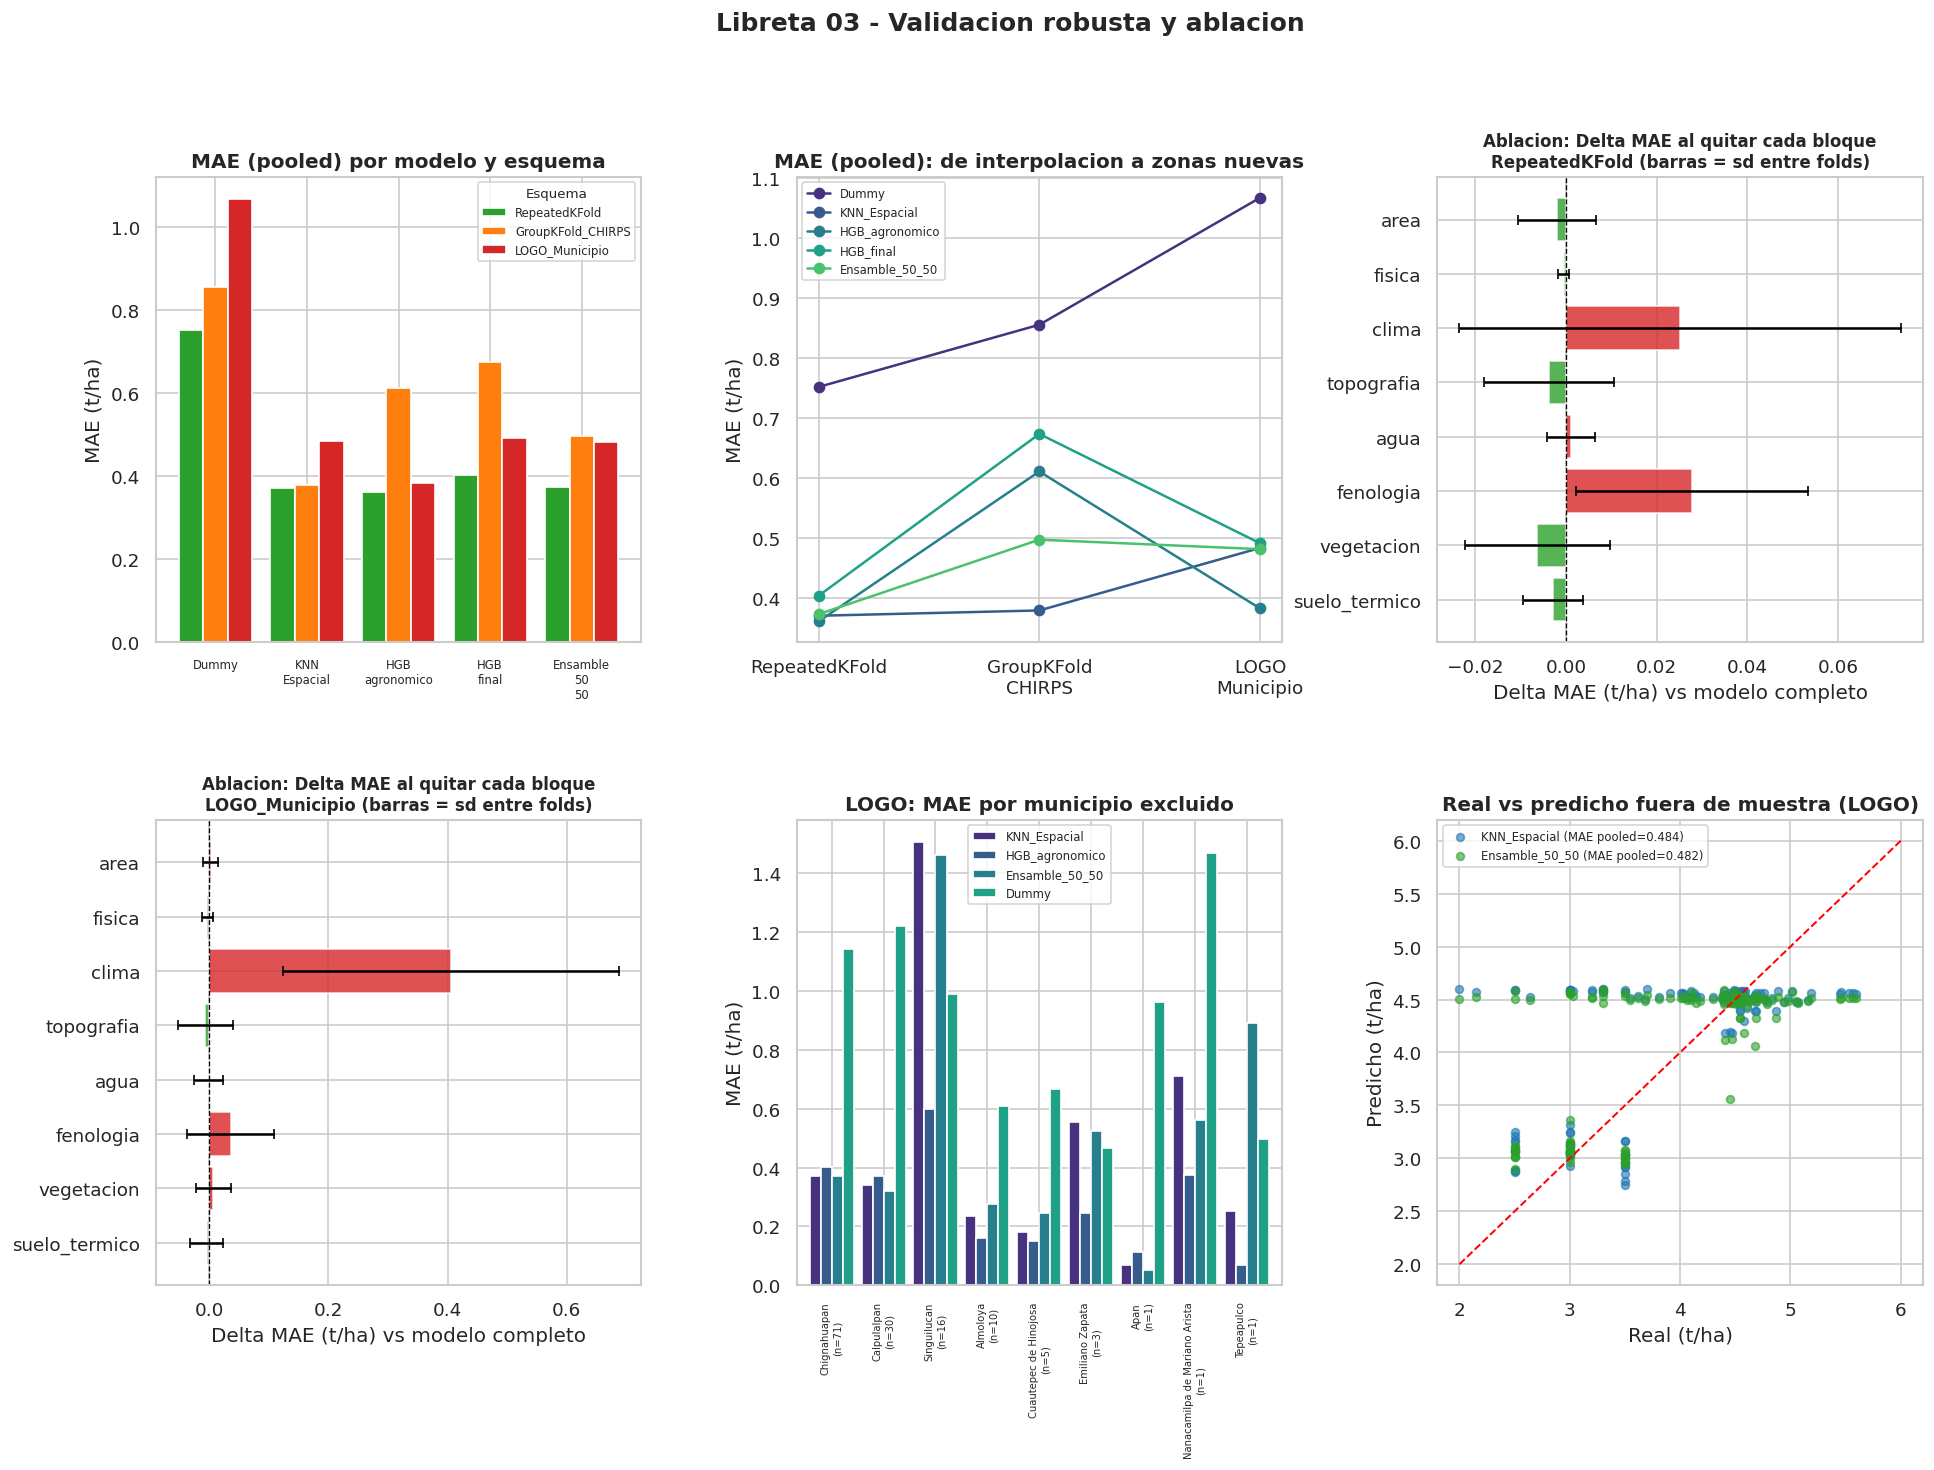


ARCHIVOS GENERADOS EN ESTA LIBRETA
Carpeta '03_validacion': 9 archivos
   - diferencias_pareadas.csv (2.4 KB)
   - logo_por_municipio.csv (1.1 KB)
   - metadatos_espaciales_validacion.csv (11.4 KB)
   - predicciones_oof_todos_esquemas.csv (39.8 KB)
   - prueba_residuos.csv (318.0 B)
   - resultados_ablacion.csv (4.7 KB)
   - resultados_por_fold.csv (11.8 KB)
   - resultados_validacion.csv (2.6 KB)
   - resumen_libreta03.json (210.0 B)

[OK] LIBRETA 03 COMPLETADA


In [11]:
# ============================================================
# 10. GRAFICOS DE RESULTADOS Y EXPORTACION DE RESUMEN
# ============================================================
fig = plt.figure(figsize=(19, 12))
gs = fig.add_gridspec(2, 3, hspace=0.38, wspace=0.32)
orden_modelos = ['Dummy', 'KNN_Espacial', 'HGB_agronomico', 'HGB_final', ENSAMBLE_NOMBRE]

# 1. MAE pooled por modelo y esquema
ax1 = fig.add_subplot(gs[0, 0])
piv = df_resultados.pivot(index='modelo', columns='esquema', values='MAE_pooled').loc[orden_modelos, ESQUEMAS]
piv.plot(kind='bar', ax=ax1, color=['#2ca02c', '#ff7f0e', '#d62728'], width=0.8)
ax1.set_title('MAE (pooled) por modelo y esquema'); ax1.set_ylabel('MAE (t/ha)'); ax1.set_xlabel('')
ax1.set_xticklabels([m.replace('_', '\n') for m in orden_modelos], rotation=0, fontsize=7)
ax1.legend(title='Esquema', fontsize=7, title_fontsize=8)

# 2. Del esquema optimista al estricto
ax2 = fig.add_subplot(gs[0, 1])
for m in orden_modelos:
    sub = df_resultados[df_resultados['modelo'] == m].set_index('esquema').loc[ESQUEMAS]
    ax2.plot(['RepeatedKFold', 'GroupKFold\nCHIRPS', 'LOGO\nMunicipio'], sub['MAE_pooled'].values, marker='o', label=m)
ax2.set_title('MAE (pooled): de interpolacion a zonas nuevas'); ax2.set_ylabel('MAE (t/ha)'); ax2.legend(fontsize=7)

# 3 y 4. Ablacion: Delta MAE al quitar cada bloque (con sd entre folds)
for pos, esquema in [((0, 2), 'RepeatedKFold'), ((1, 0), 'LOGO_Municipio')]:
    ax = fig.add_subplot(gs[pos])
    d = df_ablacion[(df_ablacion['esquema'] == esquema) & (df_ablacion['experimento'].str.startswith('Sin_'))].copy()
    d['bloque'] = d['experimento'].str.replace('Sin_', '')
    colores = ['#d62728' if v > 0 else '#2ca02c' for v in d['delta_vs_completo']]
    ax.barh(d['bloque'], d['delta_vs_completo'], xerr=d['delta_sd_folds'], color=colores, alpha=0.8, capsize=3)
    ax.axvline(0, color='black', linewidth=0.8, linestyle='--')
    ax.set_title(f'Ablacion: Delta MAE al quitar cada bloque\n{esquema} (barras = sd entre folds)', fontsize=10)
    ax.set_xlabel('Delta MAE (t/ha) vs modelo completo')

# 5. LOGO por municipio
ax5 = fig.add_subplot(gs[1, 1])
t = tabla_logo[['KNN_Espacial', 'HGB_agronomico', ENSAMBLE_NOMBRE, 'Dummy']]
t.plot(kind='bar', ax=ax5, width=0.85)
ax5.set_xticklabels([f"{i}\n(n={int(n)})" for i, n in zip(t.index, tabla_logo['n_parcelas'])], rotation=90, fontsize=6)
ax5.set_title('LOGO: MAE por municipio excluido'); ax5.set_ylabel('MAE (t/ha)'); ax5.set_xlabel('')
ax5.legend(fontsize=7)

# 6. Real vs predicho fuera de muestra (LOGO)
ax6 = fig.add_subplot(gs[1, 2])
for nombre, color in [('KNN_Espacial', '#1f77b4'), (ENSAMBLE_NOMBRE, '#2ca02c')]:
    p = predicciones_oof_todas[f'LOGO_Municipio__{nombre}']
    ax6.scatter(y, p, s=22, alpha=0.6, color=color, label=f'{nombre} (MAE pooled={mean_absolute_error(y, p):.3f})')
lim = [min(y.min(), 2), max(y.max(), 6)]
ax6.plot(lim, lim, 'r--', linewidth=1.2)
ax6.set_title('Real vs predicho fuera de muestra (LOGO)'); ax6.set_xlabel('Real (t/ha)'); ax6.set_ylabel('Predicho (t/ha)')
ax6.legend(fontsize=7)

fig.suptitle('Libreta 03 - Validacion robusta y ablacion', fontsize=15, fontweight='bold', y=0.995)
guardar_figura(fig, '04_validacion_robusta_ablacion.png', 'reports')
plt.show()

resumen_libreta03 = {
    'version': '3.0-validacion-y-ablacion',
    'semilla_global': SEMILLA,
    'semilla_hgb_final': SEMILLA_HGB_FINAL,
    'tolerancia_decision_t_ha': TOLERANCIA_DECISION,
    'cumple_regla_ensamble': cumple_regla,
    'modelo_seleccionado': ENSAMBLE_NOMBRE if cumple_regla else 'KNN_Espacial'
}
with open(CARPETAS['03_validacion'] / 'resumen_libreta03.json', 'w', encoding='utf-8') as f:
    json.dump(resumen_libreta03, f, ensure_ascii=False, indent=2)

print("\n" + "=" * 60)
print("ARCHIVOS GENERADOS EN ESTA LIBRETA")
print("=" * 60)
listar_archivos('03_validacion')
print("\n[OK] LIBRETA 03 COMPLETADA")